# 03 Análisis

**Resultado:** insights con cifra y el tamaño de la oportunidad

**Índice**

1. Cargar
2. Palanca 1: recorrido de compra
3. Palanca 2: clientes
4. Palanca 3: productos
5. Insights
6. Tamaño de la oportunidad

## 0. Librerías y rutas

In [1]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path
from dotenv import load_dotenv

# Opciones de vista
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Rutas del proyecto (el notebook vive en 03_notebooks)
RAIZ = Path.cwd().parent
ORIGINALES = RAIZ / '02_datos' / '01_Originales'
ANALITICO = RAIZ / '02_datos' / '02_Analitico'
RESULTADOS = RAIZ / '06_resultados'

# Variables de entorno (.env): ahí va DATABASE_URL
load_dotenv(RAIZ / '.env')

False

## 1. Cargar

Las tablas del notebook 02.

In [2]:
df = pd.read_pickle(ANALITICO / 'tablon_analitico.pkl')
df_grano_diario = pd.read_pickle(ANALITICO/'tablon_analitico_diario.pkl')

## 2. Palanca 1-2: Irradiacion

- ¿Llega suficiente irradiación todos los días? [1]
- ¿Es similar en ambas plantas? [2]

Se analiza la **Capatacion de luz solar** tomando un interverter por planta y analizando tramo - inverter -   en cada planta



In [3]:
# Se toma dos inverter al azar para convertir el DF a nivel Planta-Tramo y analizar la captacion solar
# Se machaca inverter
captacion = (df.loc[(df['id_inversor']=='1BY6WEcLGh8j5v7') | (df['id_inversor']=='xMbIugepa2P7lBB'),
             'id_planta':'temperatura_modulo_c'])


In [4]:
# agregado por planta con condicion de irradiacion <> 0 (Noche) para las medias de irradiacion

def sin_sol(x):
    return x[x != 0].mean()

resultado_captacion = captacion.groupby('id_planta').agg({
    'irradiacion_wh_m2' :sin_sol, #media solo con valores !0
    'temperatura_ambiente_c' : 'mean',
    'temperatura_modulo_c' : 'mean'
}).round(2)



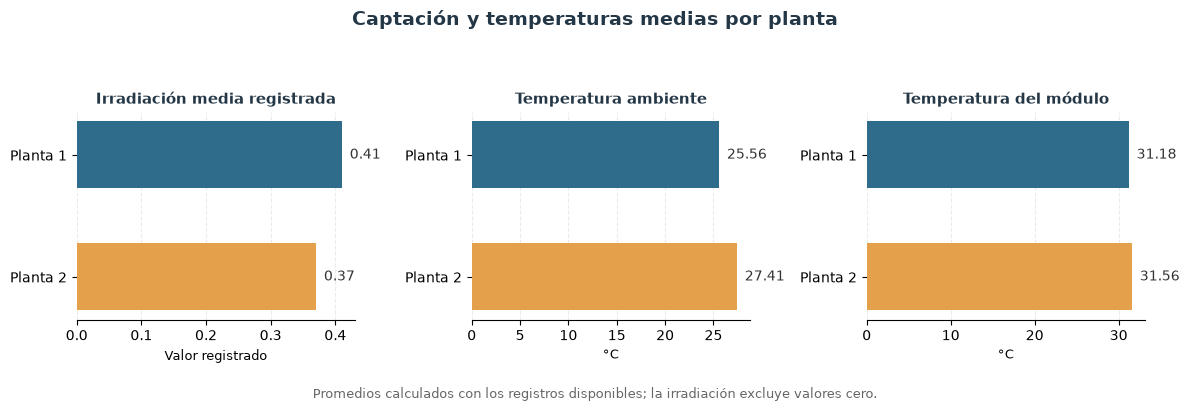

In [5]:
# ── Comparación de captación por planta ─────────

metricas = [
    ('irradiacion_wh_m2', 'Irradiación media registrada', 'Valor registrado'),
    ('temperatura_ambiente_c', 'Temperatura ambiente', '°C'),
    ('temperatura_modulo_c', 'Temperatura del módulo', '°C')
]

colores = {
    'Planta 1': '#2F6B8A',
    'Planta 2': '#E5A04B'
}

fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    columna, titulo, unidad = metrica
    valores = resultado_captacion[columna]

    for posicion, planta in enumerate(valores.index):
        valor = valores.loc[planta]
        eje.barh(
            posicion,
            valor,
            color=colores.get(planta, '#777777'),
            height=0.55
        )
        eje.text(
            valor,
            posicion,
            f'  {valor:.2f}',
            va='center',
            fontsize=10,
            color='#333333'
        )

    eje.set_title(titulo, fontsize=11, weight='bold', color='#243746')
    eje.set_xlabel(unidad, fontsize=9)
    eje.set_yticks(range(len(valores.index)))
    eje.set_yticklabels(valores.index)
    eje.invert_yaxis()
    eje.spines['top'].set_visible(False)
    eje.spines['right'].set_visible(False)
    eje.spines['left'].set_visible(False)
    eje.grid(axis='x', linestyle='--', alpha=0.25)
    eje.set_axisbelow(True)

fig.suptitle(
    'Captación y temperaturas medias por planta',
    fontsize=14,
    weight='bold',
    color='#243746'
)
fig.text(
    0.5,
    0.01,
    'Promedios calculados con los registros disponibles; la irradiación excluye valores cero.',
    ha='center',
    fontsize=9,
    color='#666666'
)

plt.tight_layout(rect=[0, 0.06, 1, 0.90])
plt.show()

### Insight 5 

La irradiación media registrada es algo menor en Planta 2 (**0,37 frente a 0,42**), pero la temperatura media del módulo es prácticamente igual (**31,56 °C frente a 31,80 °C**). En este resumen no se observa una señal clara de problema de captación en Planta 2. Conviene comparar con las *fases de conversion e inversion* con la irradiacion antes de descartar una anomalía.

_____________________________________________________________

#### Distribucion por hora [3]

La captacion solar del inverter en cada hora en cada planta


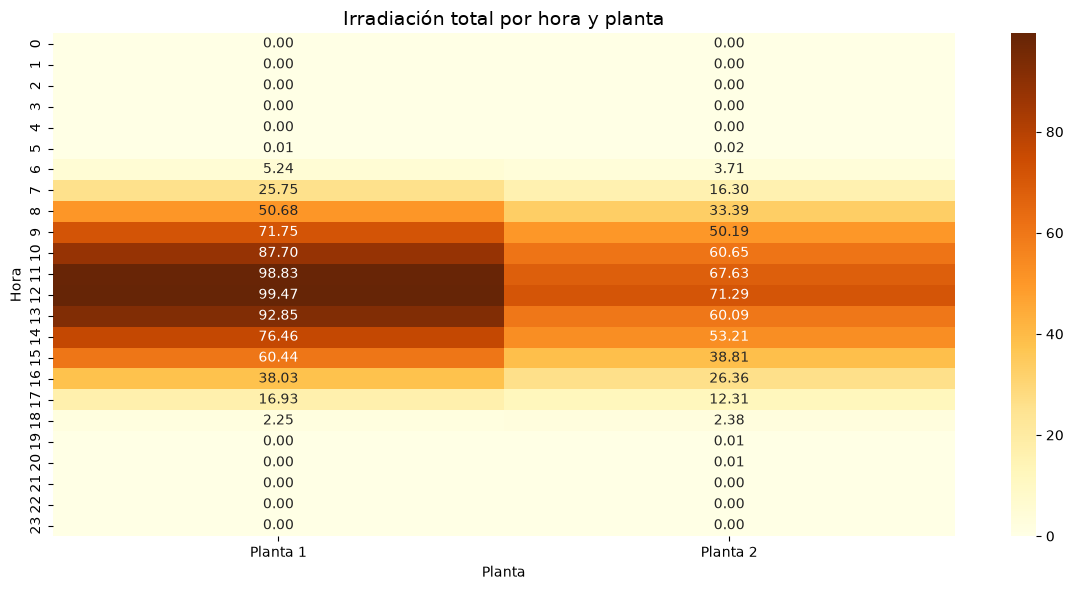

In [6]:
# tabla cruza con las sumas de los tramos de 15 minutos de luz solar para comparacion por hora
temp_hora = pd.crosstab(
    captacion['hora'],
    captacion['id_planta'],
    values=captacion['irradiacion_wh_m2'],
    aggfunc='sum'
)

plt.figure(figsize=(12, 6))
sns.heatmap(temp_hora, annot=True, fmt='.2f', cmap='YlOrBr')
plt.title('Irradiación total por hora y planta', fontsize=14)
plt.xlabel('Planta')
plt.ylabel('Hora')
plt.tight_layout()
plt.show()

## 3. Palanca 3-4: Generacion DC y AC

- ¿Cuál es la relación entre irradiación y generación de DC/AC? [1]
- ¿Se ve afectada en algún momento por la temperatura ambiente o del módulo? [2]
- ¿Es similar en ambas plantas? [3]


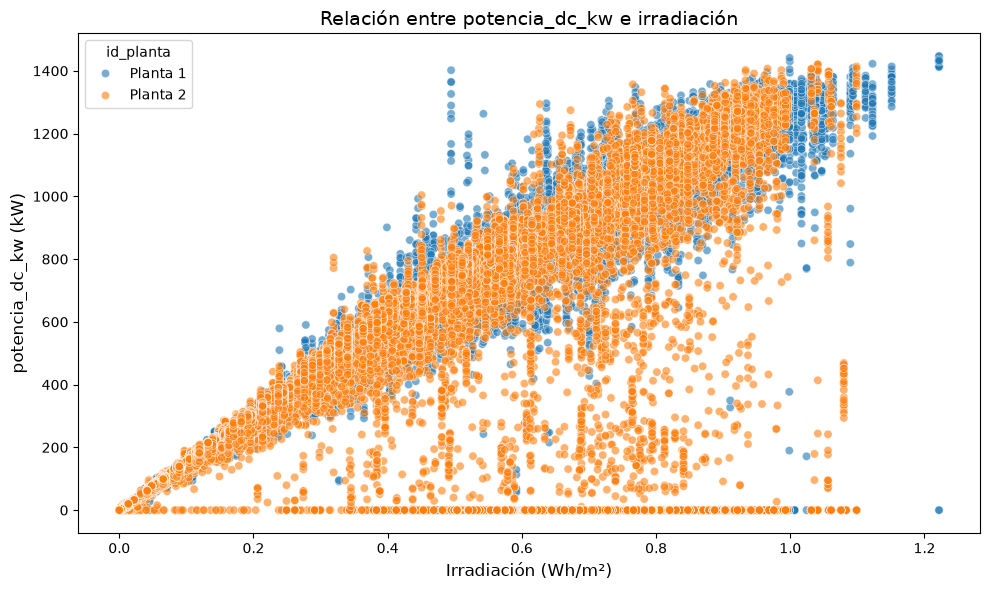

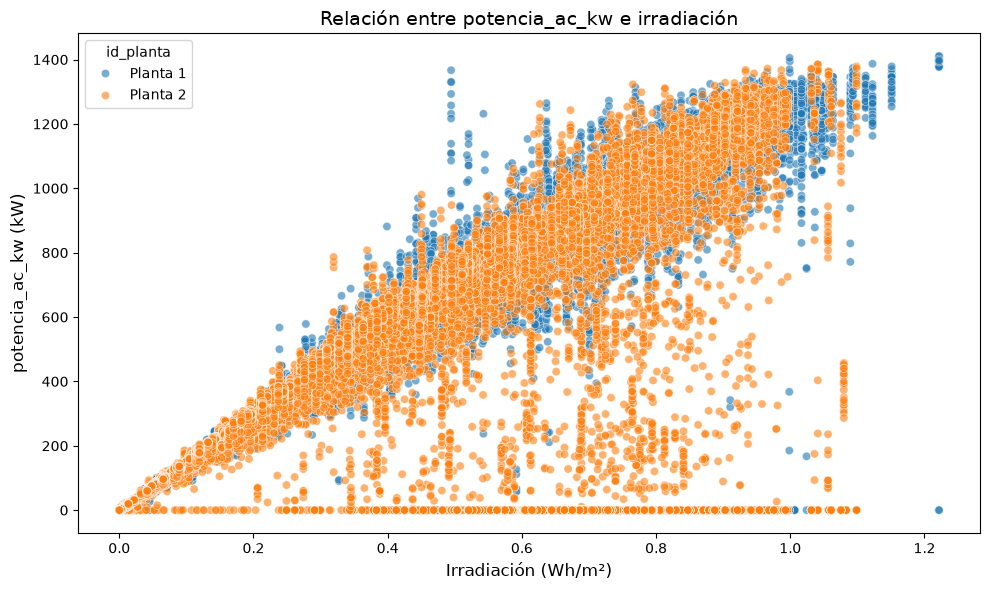

In [7]:
# Correlación entre potencia DC/AC e irradiación

df_grafico = df.reset_index(drop=True)
cols = ['potencia_dc_kw', 'potencia_ac_kw']

for n in cols:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df_grafico,
        x='irradiacion_wh_m2',
        y=n, #cada potencia
        hue='id_planta',
        alpha=0.6
    )
    plt.title(f'Relación entre {n} e irradiación', fontsize=14)
    plt.xlabel('Irradiación (Wh/m²)', fontsize=12)
    plt.ylabel(f'{n} (kW)', fontsize=12)
    plt.tight_layout()
    plt.show()



### Insight 6. Caídas de potencia en Planta 2 compatibles con paradas

La relación entre irradiación y potencia muestra caídas puntuales de potencia DC y AC en Planta 2, incluso cuando hay irradiación. El patrón es consistente con posibles paradas o indisponibilidad de inversores, aunque el gráfico por sí solo no confirma la causa.

Se identificara cuándo ocurren esas caídas, qué inversores están afectados y cuánto duran; después, contrastarlas con registros de operación para estimar la energía perdida y decidir si hace falta una inspección en planta.

______________________________________________________________________________________________________

- ¿Cómo se distribuye a lo largo del día? [4]
- ¿Es constante a lo largo de los días? [5]
- ¿Es constante en todos los inverters? [6]
- ¿Ha habido momentos de fallos? [7]

In [8]:
# Dataframe en agregacion con planta, fecha, hora, con la media de potencia_dc_kw y de potencia_ac_kw
# para poder ver la distribucion horararia a lo largo del dia

df['fecha'] = df.index.date
df_analisis_horario = df.groupby(['id_planta','fecha','hora']).agg({
    'potencia_dc_kw': 'mean',
    'potencia_ac_kw': 'mean'
}).reset_index()

df_analisis_horario

,id_planta,fecha,hora,potencia_dc_kw,potencia_ac_kw
0,Planta 1,2020-05-15,0,0.00,0.00
1,Planta 1,2020-05-15,1,0.00,0.00
2,Planta 1,2020-05-15,2,0.00,0.00
3,Planta 1,2020-05-15,3,0.00,0.00
4,Planta 1,2020-05-15,4,0.00,0.00
...,...,...,...,...,...
1607,Planta 2,2020-06-17,19,0.00,0.00
1608,Planta 2,2020-06-17,20,0.00,0.00
1609,Planta 2,2020-06-17,21,0.00,0.00
1610,Planta 2,2020-06-17,22,0.00,0.00


In [9]:
# ── Función de potencia por hora y día ─────────

def graficar_horas_por_dia(datos, planta, columna, etiqueta, color, n_columnas=2):
    tabla = datos.loc[datos['id_planta'] == planta].copy()
    tabla['fecha'] = pd.to_datetime(tabla['fecha']).dt.normalize()

    # fechas en columnas, horas en filas: un panel por día
    matriz = tabla.pivot_table(
        index='hora',
        columns='fecha',
        values=columna,
        aggfunc='mean'
    )

    horas = list(matriz.index)
    fechas = list(matriz.columns)
    n_filas = int(np.ceil(len(fechas) / n_columnas))

    fig, ejes = plt.subplots(
        n_filas,
        n_columnas,
        figsize=(12, 2.4 * n_filas),
        sharex=True,
        sharey=True,
        squeeze=False
    )
    ejes = ejes.flatten()

    # asegura enteros: con horas como texto, las barras se centran en 0,1,2... y las marcas se desalinean
    horas = [int(hora) for hora in matriz.index]

    for posicion, fecha in enumerate(fechas):
        eje = ejes[posicion]
        eje.bar(horas, matriz[fecha], color=color, width=0.8, align='center')
        eje.set_title(fecha.strftime('%Y-%m-%d'), fontsize=9, weight='bold')
        eje.grid(axis='y', linestyle='--', alpha=0.25)
        eje.set_axisbelow(True)
        eje.set_xticks(range(0, 24, 3))
        eje.set_xticklabels(range(0, 24, 3), ha='center')
        eje.set_xlim(-0.5, 23.5)
        eje.margins(x=0)
        eje.tick_params(labelsize=7, labelbottom=True, labelrotation=0)

    for posicion in range(len(fechas), len(ejes)):
        fig.delaxes(ejes[posicion])

    # con ejes compartidos basta marcar las horas una vez
    ejes[0].set_xticks(range(0, 24, 3))

    fig.suptitle(f'{etiqueta} por hora y día | {planta}', fontsize=13, weight='bold')
    fig.supxlabel('Hora del día', fontsize=9)
    fig.supylabel(etiqueta, fontsize=9)
    fig.tight_layout(rect=[0, 0.01, 1, 0.96])
    plt.show()

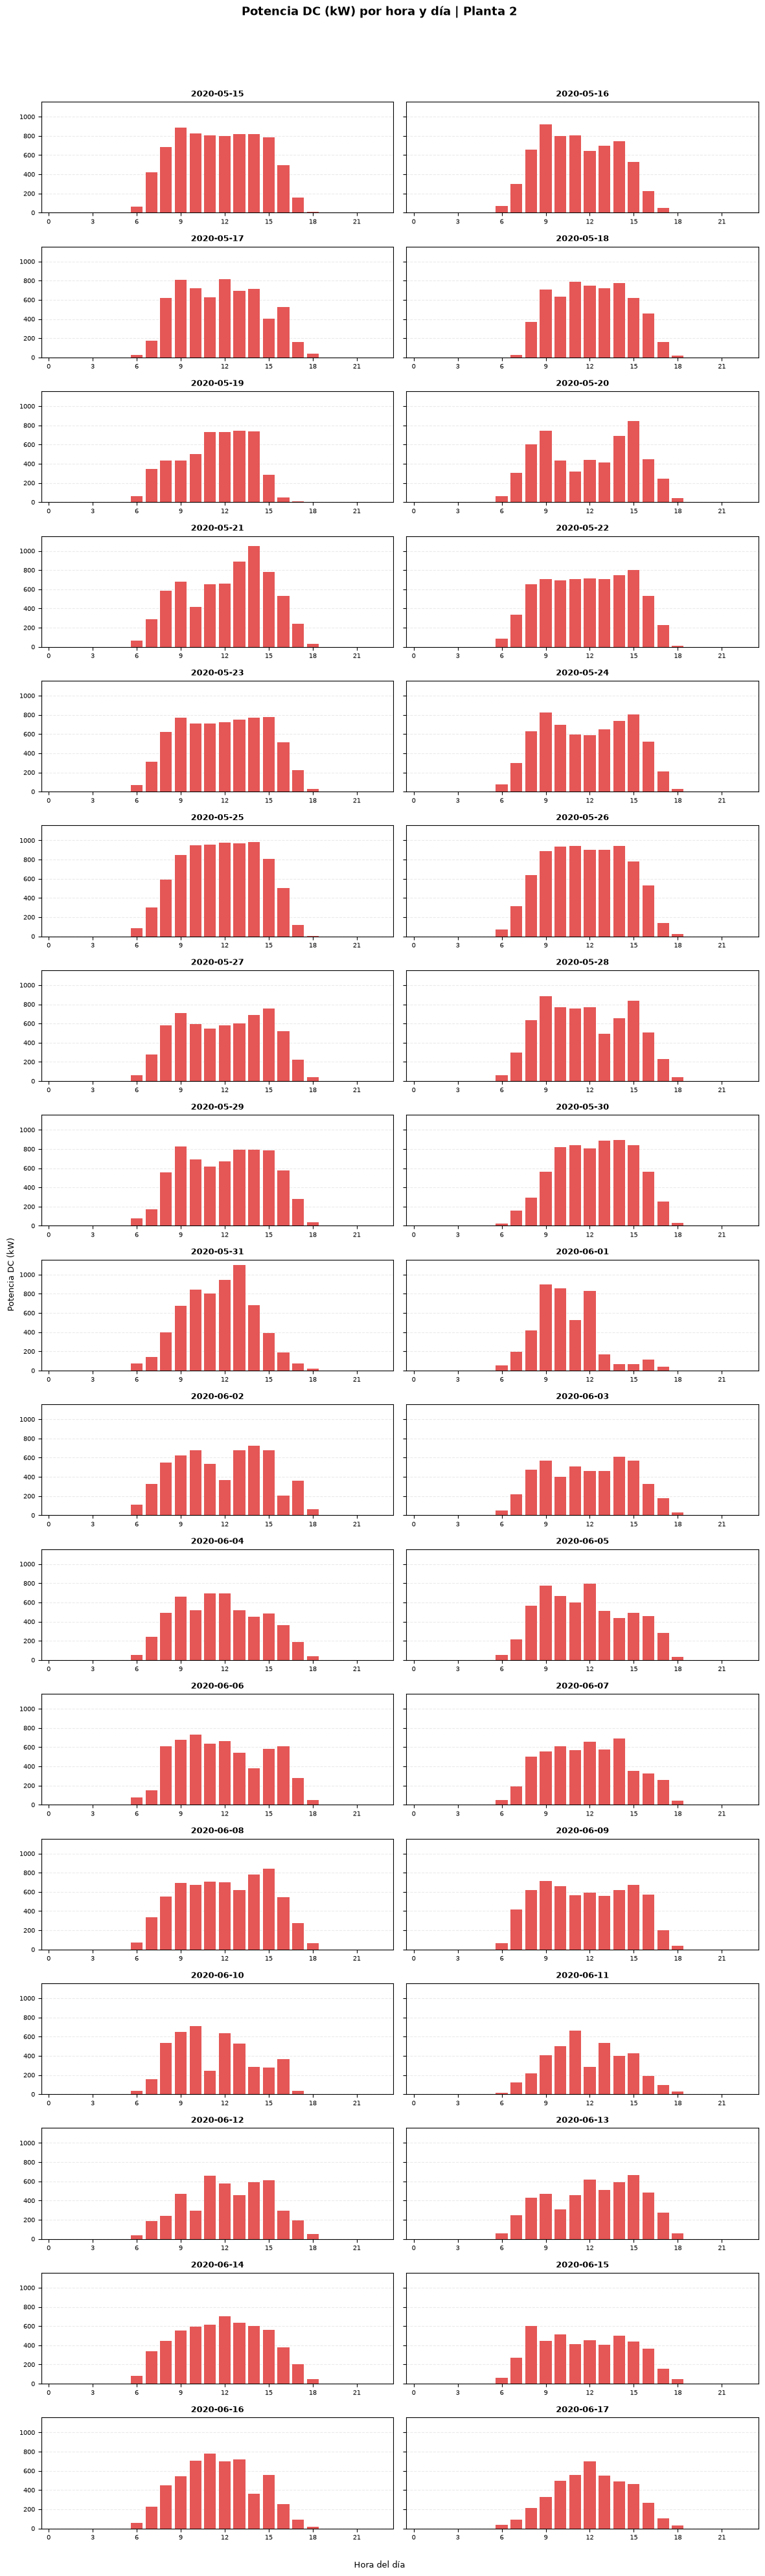

In [10]:
graficar_horas_por_dia(
    df_analisis_horario,
    'Planta 2',
    'potencia_dc_kw',
    'Potencia DC (kW)',
    '#e45756'
)

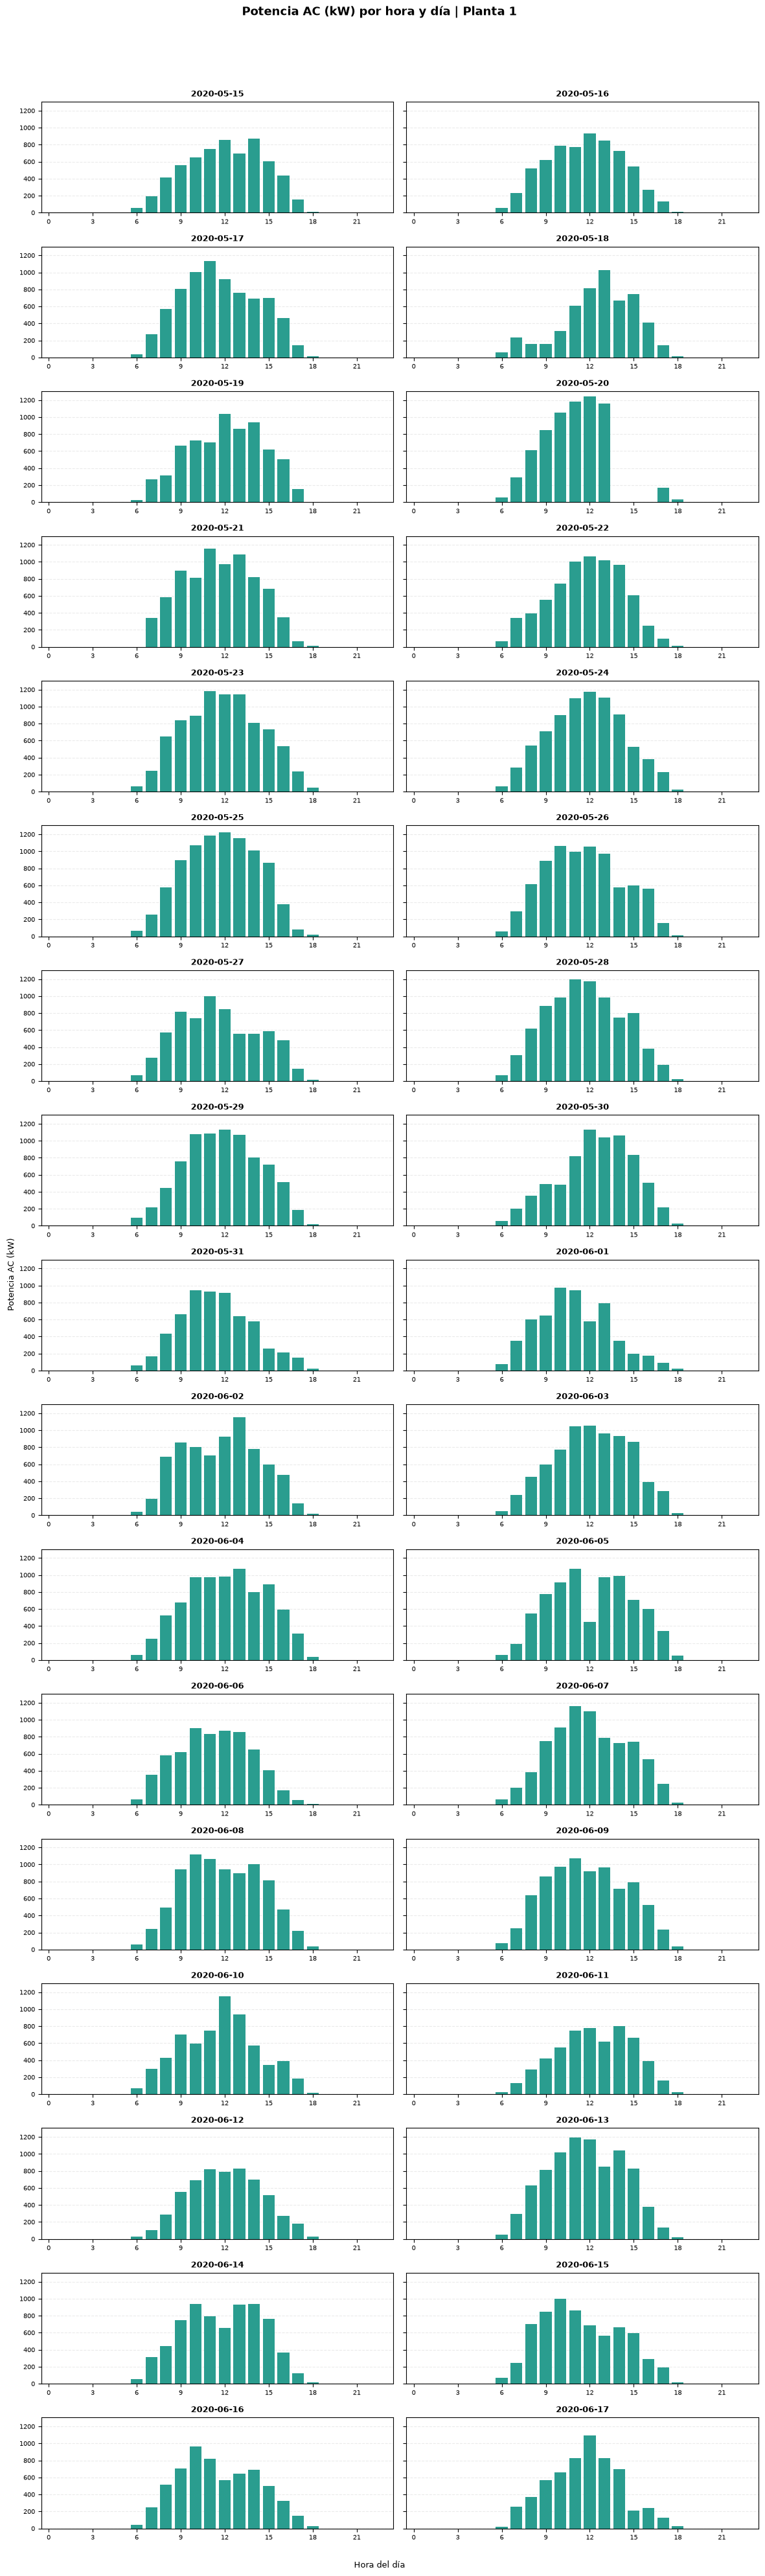

In [38]:
graficar_horas_por_dia(
    df_analisis_horario,
    'Planta 1',
    'potencia_ac_kw',
    'Potencia AC (kW)',
    '#2a9d8f'
)

### Análisis horario de potencia

Al revisar el comportamiento por hora de la potencia DC y AC en los 34 días, se identificaron los días donde las caídas son más marcadas respecto a la forma esperada de la curva. Sobre esos días se revisará el comportamiento de cada inversor.

Para elegir los días se compara cada jornada contra el día típico. El día típico es **la mediana de la potencia AC de cada hora a lo largo de los 34 días***, y el ratio de un día es lo que produjo frente a esa mediana. Un ratio de 0,73 significa que ese día generó el **73 % de un día normal.**

Se toman los cinco días con el ratio más bajo de cada planta. Junto al ratio queda una columna con el número de inversores que traen menos registros que el mejor del día, para saber antes de bajar al detalle si la caída viene de generación o de equipos que dejaron de reportar. Ningún día se descarta por cobertura: esa columna solo orienta la revisión.

In [12]:
# ── Días frente al día típico, con la cobertura al lado ─────────

horario = df_analisis_horario.copy()
horario['fecha'] = pd.to_datetime(horario['fecha'])
horas_luz = list(range(6, 20))

ranking = []
for planta in sorted(horario['id_planta'].unique()):
    datos = horario.loc[horario['id_planta'] == planta]
    # día típico: mediana de cada hora en los 34 días
    tipica = datos.groupby('hora')['potencia_ac_kw'].median()

    for fecha, dia in datos.groupby('fecha'):
        dia = dia.set_index('hora').reindex(horas_luz)
        observado = dia['potencia_ac_kw'].sum()
        esperado = tipica.loc[horas_luz].sum()

        ranking.append({
            'id_planta': planta,
            'fecha': fecha,
            'ratio_vs_tipica': observado / esperado
        })

ranking = pd.DataFrame(ranking)

# cuántos inversores vienen incompletos cada día
cobertura = []
for planta, archivo in [('Planta 1', 'Planta1_Generacion.pkl'), ('Planta 2', 'Planta2_Generacion.pkl')]:
    tabla = pd.read_pickle(ANALITICO / archivo)
    tabla['fecha'] = tabla['fecha_hora'].dt.normalize()

    for fecha, dia in tabla.groupby('fecha'):
        por_inversor = dia.groupby('id_inversor')['fecha_hora'].nunique()
        cobertura.append({
            'id_planta': planta,
            'fecha': fecha,
            'inversores': len(por_inversor),
            'inversores_incompletos': int((por_inversor < por_inversor.max()).sum())
        })

cobertura = pd.DataFrame(cobertura)
ranking = ranking.merge(cobertura, on=['id_planta', 'fecha'], how='left')
ranking = ranking.sort_values(['id_planta', 'ratio_vs_tipica'])

In [13]:
# ── Tabla de días frente al día típico ─────────

peores = ranking.groupby('id_planta', group_keys=False).head(5).reset_index(drop=True)
peores['fecha'] = peores['fecha'].dt.strftime('%Y-%m-%d')

(
    peores.style
    .background_gradient(subset=['ratio_vs_tipica'], cmap='RdYlGn', vmin=0.7, vmax=1.1)
    .format({'ratio_vs_tipica': '{:.2f}'})
    .set_caption('Cinco días con menor producción frente al día típico por planta')
)

,id_planta,fecha,ratio_vs_tipica,inversores,inversores_incompletos
0,Planta 1,2020-05-18,0.73,22,0
1,Planta 1,2020-06-11,0.76,22,0
2,Planta 1,2020-06-01,0.79,22,0
3,Planta 1,2020-06-12,0.79,22,0
4,Planta 1,2020-06-17,0.81,22,0
5,Planta 2,2020-06-11,0.63,22,0
6,Planta 2,2020-06-01,0.68,22,0
7,Planta 2,2020-06-17,0.70,22,0
8,Planta 2,2020-06-10,0.72,22,0
9,Planta 2,2020-06-15,0.75,22,0


### Insight 7


Los cinco días de menor producción de cada planta tienen los inversores completos, así que las caídas son de **generación** y no de registros. El peor día baja a 0,63, es decir 37 % por debajo de un día típico, y en Planta 1 el mínimo es **0,73**, 27 % por debajo. Ninguno de esos días se explica por falta de datos: son los cuatro o cinco equipos de cada planta los que hay que revisar. Sobre esta selección se hace el desglose por inversor.

In [ ]:
# Registros de los cinco peores días de cada planta

seleccion = ranking.groupby('id_planta', group_keys=False).head(5)[['id_planta', 'fecha']].copy()
seleccion['fecha'] = pd.to_datetime(seleccion['fecha'])

df_problemas = df.reset_index().copy()
df_problemas['fecha_dia'] = pd.to_datetime(df_problemas['fecha_hora']).dt.normalize()

df_problemas = df_problemas.merge(
    seleccion.rename(columns={'fecha': 'fecha_dia'}),
    on=['id_planta', 'fecha_dia'],
    how='inner'
)

#### ¿Es constante en todos los inverters? [6]

In [ ]:
# Grafico para cada planta y dia, y que sea un heatmap con cada inverter en las filas y cada hora en las columnas, y el valor la media de potencia_dc_kw
for planta in df_problemas['id_planta'].unique():
    df_planta = df_problemas[df_problemas['id_planta'] == planta]
    for fecha in df_planta['fecha'].unique():
        df_dia = df_planta[df_planta['fecha'] == fecha]
        pivot = df_dia.pivot_table(index='id_inversor', columns='hora', values='potencia_dc_kw', aggfunc='mean')

        plt.figure(figsize=(20, 20))
        sns.heatmap(pivot, cmap='viridis', annot=True, fmt='.1f')
        plt.title(f'Potencia DC (kW) - Planta {planta} - Fecha {fecha}', fontsize=14, fontweight='bold')
        plt.xlabel('Hora')
        plt.ylabel('ID Inversor')
        plt.show()